# **2. Khám phá dữ liệu (EDA)**

Vẽ biểu đồ để hiểu phân phối doanh thu và các yếu tố ảnh hưởng. Notebook này **không thay đổi dữ liệu**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)


# [UPDATED] Đọc dữ liệu sạch do notebook 01 lưu, nên notebook này chạy độc lập được
my_data = pd.read_csv('data/processed/rossmann_clean.csv', parse_dates=['Date'], dtype={'StateHoliday': str})
print(my_data.shape)

(844338, 17)


**2.1 Phân phối của doanh thu (Sales)**

count    844338.0
mean       6956.0
std        3103.8
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: Sales, dtype: float64
Độ lệch (skewness): 1.59


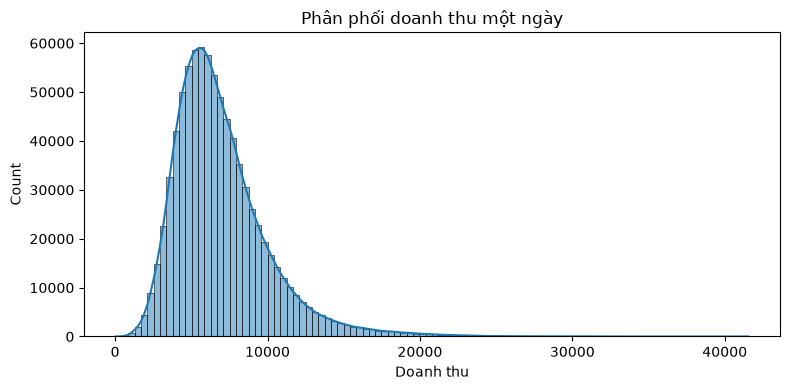

In [2]:
print(my_data['Sales'].describe().round(1))
print('Độ lệch (skewness):', round(my_data['Sales'].skew(), 2))
plt.figure(figsize=(8, 4))
sns.histplot(my_data['Sales'], bins=100, kde=True)
plt.title('Phân phối doanh thu một ngày')
plt.xlabel('Doanh thu')
save_fig('sales_hist')

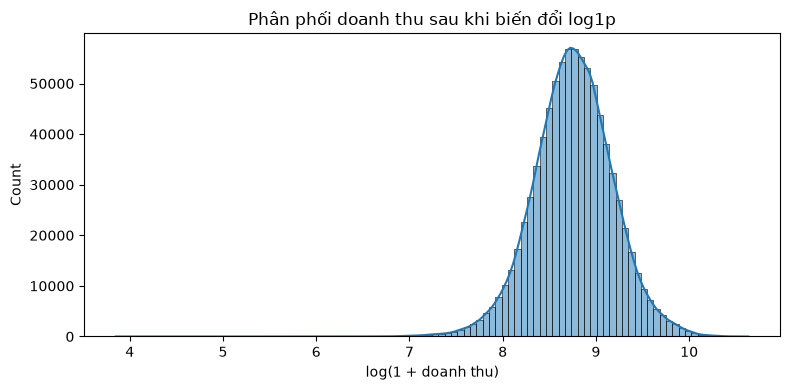

In [3]:
# [UPDATED] Chỉ vẽ phân phối sau log, KHÔNG ghi đè cột Sales (trước đây ghi đè làm các biểu đồ sau bị vẽ trên thang log)
plt.figure(figsize=(8, 4))
sns.histplot(np.log1p(my_data['Sales']), bins=100, kde=True)
plt.title('Phân phối doanh thu sau khi biến đổi log1p')
plt.xlabel('log(1 + doanh thu)')
save_fig('sales_log_hist')

**Nhận xét:** doanh thu trung bình 6.956, trung vị 6.369, độ lệch 1,59 → phân phối **lệch phải** (ít ngày doanh thu rất cao kéo đuôi bên phải). Sau `log1p` phân phối cân đối hơn, nên mô hình sẽ học trên log(doanh thu).

**2.2 Khuyến mãi và loại cửa hàng**

Tỷ lệ quan sát (%): {0: 55.36, 1: 44.64}
         mean  median
Promo                
0      5930.0  5459.0
1      8229.0  7650.0


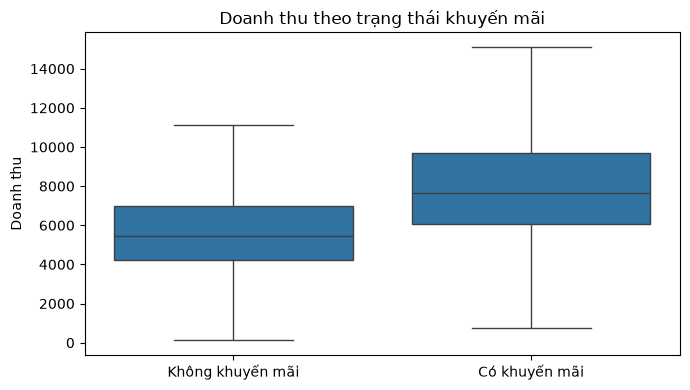

In [4]:
promo_share = my_data['Promo'].value_counts(normalize=True).mul(100).round(2)
print('Tỷ lệ quan sát (%):', promo_share.to_dict())
print(my_data.groupby('Promo')['Sales'].agg(['mean', 'median']).round(0))
plt.figure(figsize=(7, 4))
sns.boxplot(data=my_data, x='Promo', y='Sales', showfliers=False)
plt.xticks([0, 1], ['Không khuyến mãi', 'Có khuyến mãi'])
plt.xlabel('')
plt.ylabel('Doanh thu')
plt.title('Doanh thu theo trạng thái khuyến mãi')
save_fig('promo_box')

**Nhận xét:** 44,64% số ngày có khuyến mãi. Doanh thu trung bình ngày có khuyến mãi là 8.229, cao hơn khoảng 39% so với ngày không có (5.930). Hai hộp vẫn chồng lên nhau nên không phải ngày khuyến mãi nào cũng cao hơn.

           count  median     mean
StoreType                        
a            602  6481.0   6913.0
b             17  9745.0  10112.0
c            148  6646.0   6918.0
d            348  6695.0   6824.0


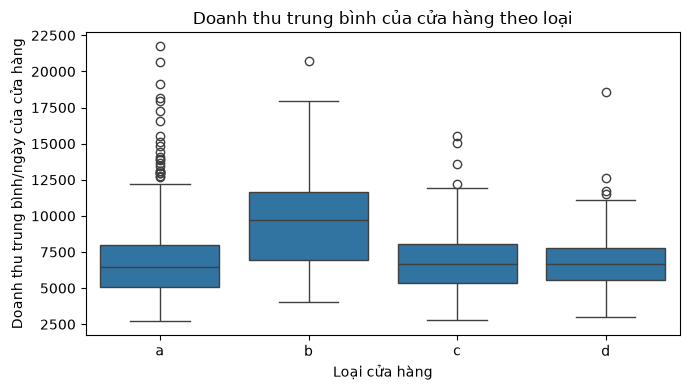

In [5]:
# [UPDATED] Sửa lỗi gom nhóm: tính doanh thu trung bình của MỖI CỬA HÀNG (trước đây gom theo giá trị Sales nên sai)
store_mean = my_data.groupby(['StoreType', 'Store'], as_index=False)['Sales'].mean()
print(store_mean.groupby('StoreType')['Sales'].agg(['count', 'median', 'mean']).round(0))
plt.figure(figsize=(7, 4))
sns.boxplot(data=store_mean, x='StoreType', y='Sales', order=['a', 'b', 'c', 'd'])
plt.xlabel('Loại cửa hàng')
plt.ylabel('Doanh thu trung bình/ngày của cửa hàng')
plt.title('Doanh thu trung bình của cửa hàng theo loại')
save_fig('storetype_box')

**Nhận xét:** loại b (chỉ 17 cửa hàng) có doanh thu trung bình/ngày cao nhất (trung vị 9.745); ba loại a, c, d gần như ngang nhau (khoảng 6.500–6.700).

**2.3 Doanh thu theo thời gian**

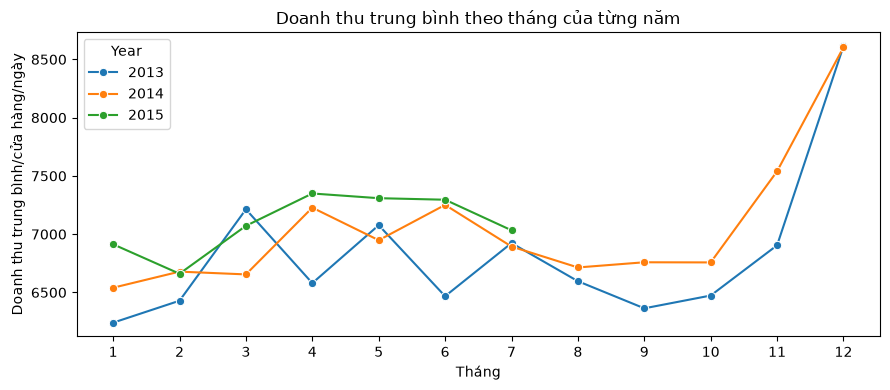

In [6]:
# [UPDATED] Dùng doanh thu TRUNG BÌNH thay vì tổng: 180 cửa hàng thiếu dữ liệu 07–12/2014 làm tổng doanh thu giảm giả tạo
monthly = my_data.set_index('Date')['Sales'].resample('MS').mean().reset_index()
monthly['Year'] = monthly['Date'].dt.year
monthly['Month'] = monthly['Date'].dt.month
plt.figure(figsize=(9, 4))
sns.lineplot(data=monthly, x='Month', y='Sales', hue='Year', marker='o', palette='tab10')
plt.xticks(range(1, 13))
plt.xlabel('Tháng')
plt.ylabel('Doanh thu trung bình/cửa hàng/ngày')
plt.title('Doanh thu trung bình theo tháng của từng năm')
save_fig('monthly_sales')

**Nhận xét:** doanh thu tăng mạnh vào tháng 11–12 (mùa lễ cuối năm) và lặp lại ở cả 2013, 2014. Năm 2015 nhìn chung cao hơn cùng kỳ các năm trước → có xu hướng tăng nhẹ. *Lưu ý:* nếu vẽ bằng tổng doanh thu, nửa cuối 2014 sẽ thấp giả tạo do 180 cửa hàng bị thiếu dữ liệu.

             size    mean  median
DayOfWeek                        
1          137557  8216.0  7539.0
2          143955  7088.0  6502.0
3          141922  6729.0  6210.0
4          134626  6768.0  6246.0
5          138633  7073.0  6581.0
6          144052  5875.0  5425.0
7            3593  8225.0  6876.0


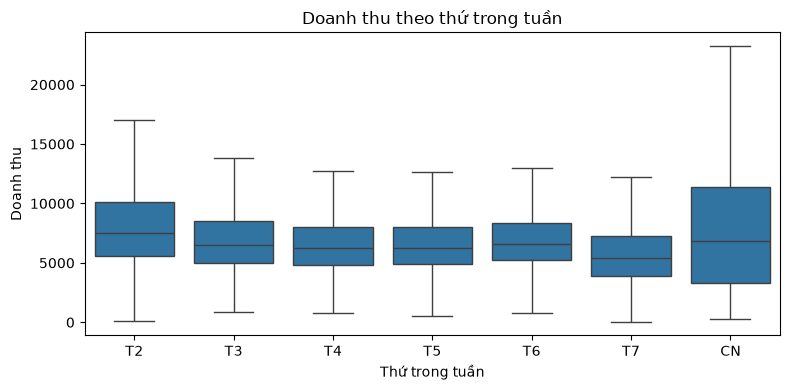

In [7]:
print(my_data.groupby('DayOfWeek')['Sales'].agg(['size', 'mean', 'median']).round(0))
plt.figure(figsize=(8, 4))
sns.boxplot(data=my_data, x='DayOfWeek', y='Sales', showfliers=False)
plt.xticks(range(7), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'])
plt.xlabel('Thứ trong tuần')
plt.ylabel('Doanh thu')
plt.title('Doanh thu theo thứ trong tuần')
save_fig('dow_box')

**Nhận xét:** thứ Hai bán chạy nhất (trung bình 8.216), thứ Bảy thấp nhất (5.875). Chủ nhật chỉ có 3.593 quan sát vì phần lớn cửa hàng đóng cửa, nên con số của Chủ nhật không đại diện cho cả chuỗi.

**2.4 Quan hệ giữa các biến**

Customers                    0.824
Promo                        0.368
SchoolHoliday                0.039
CompetitionOpenSinceYear     0.005
CompetitionOpenSinceMonth   -0.018
CompetitionDistance         -0.029
Promo2SinceWeek             -0.058
Promo2                      -0.128
Promo2SinceYear             -0.128
DayOfWeek                   -0.179
Name: Sales, dtype: float64


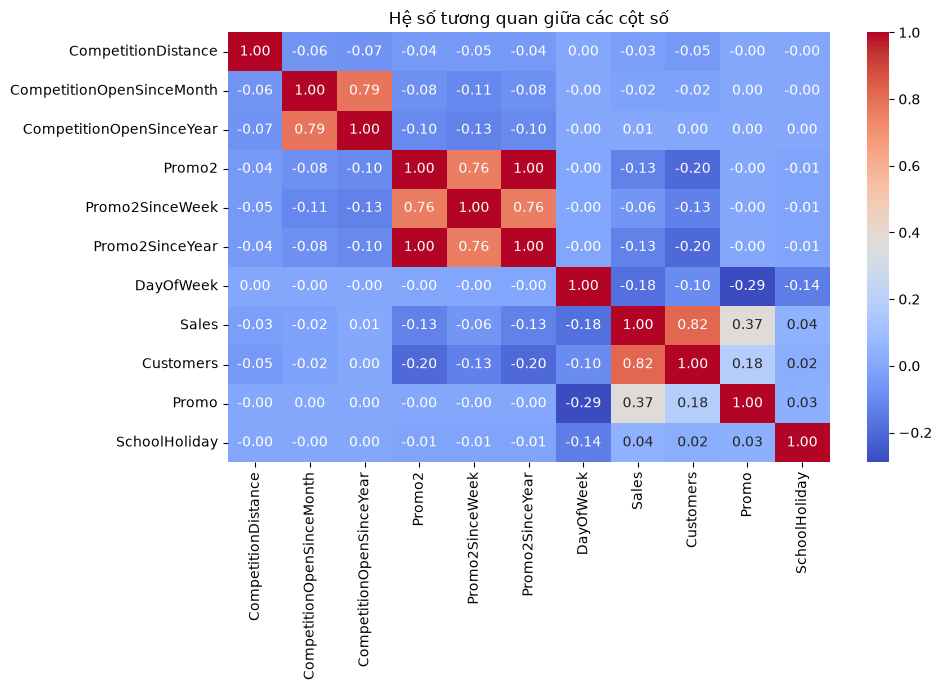

In [8]:
# [UPDATED] Chỉ lấy cột số (numeric_only) để tránh lỗi với cột ngày và cột chữ
corr = my_data.drop(columns='Store').corr(numeric_only=True)
print(corr['Sales'].drop('Sales').sort_values(ascending=False).round(3))
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Hệ số tương quan giữa các cột số')
save_fig('corr_heatmap')

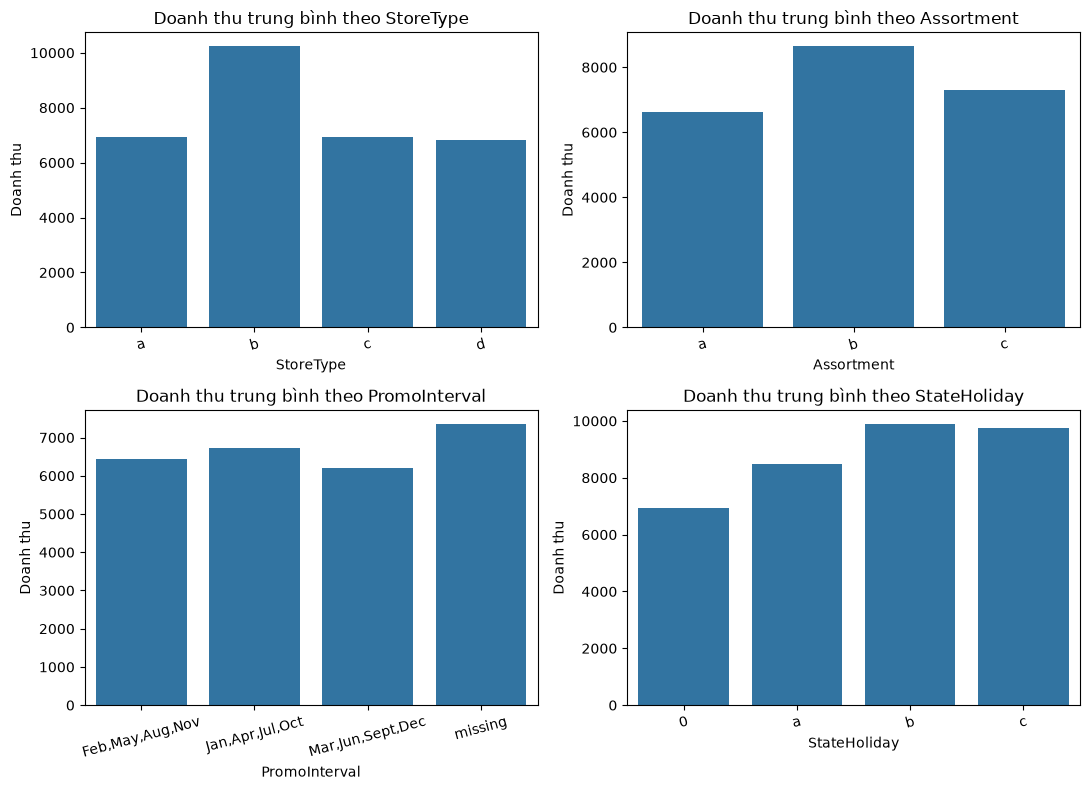

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), ['StoreType', 'Assortment', 'PromoInterval', 'StateHoliday']):
    sns.barplot(data=my_data, x=col, y='Sales', ax=ax, errorbar=None, order=sorted(my_data[col].unique()))
    ax.set_title(f'Doanh thu trung bình theo {col}')
    ax.set_ylabel('Doanh thu')
    ax.tick_params(axis='x', labelrotation=15)
save_fig('category_bars')

**Nhận xét:** `Customers` tương quan rất mạnh với doanh thu (0,82) nhưng chỉ biết sau khi bán xong → không dùng để dự đoán. `Promo` có tương quan dương rõ nhất (0,37) trong các cột còn lại. Ngày lễ (a, b, c) có doanh thu trung bình cao hơn ngày thường vì chỉ một số ít cửa hàng mở cửa vào ngày lễ.